## TP 2 : Estimateur par projection

In [47]:
import numpy as np
import matplotlib.pyplot as plt

Exercice 1

1.

In [48]:
X = np.random.uniform(size=100)
epsilon = np.random.normal(0,1,size=100)
sigma = 0.2

def f(x):
    return((x**2*2**(x-1) - (x-0.5)**3)*np.sin(10*x))

Y = f(X) + sigma*epsilon

2.

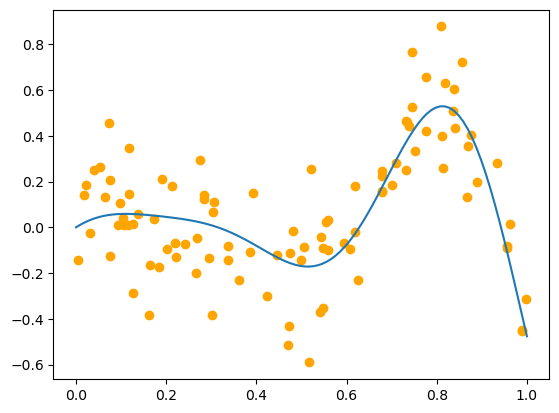

In [59]:
t = np.linspace(0,1,100)
plt.plot(t,f(t))
plt.scatter(X,Y,color='orange')

3.

(a)

In [62]:
def phi(n,x):
    if(n == 1):
        return(np.ones_like(x))
    a = np.sqrt(2)
    if(n % 2 == 0):
        k = n // 2
        return(a*np.cos(2*np.pi*k*x))
    else:
        k = (n+1) // 2
        return(a*np.sin(2*np.pi*k*x))

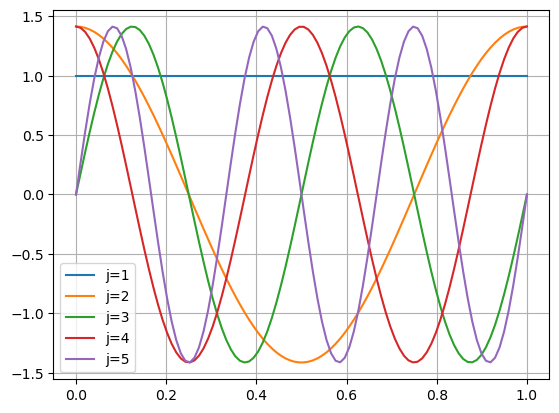

In [63]:
plt.plot(t,phi(1,t),label='j=1')
plt.plot(t,phi(2,t),label='j=2')
plt.plot(t,phi(3,t),label='j=3')
plt.plot(t,phi(4,t),label='j=4')
plt.plot(t,phi(5,t),label='j=5')
plt.grid()
plt.legend()
plt.show()

(b)

In [68]:
def theta_hat(j,X,Y):
   return(np.mean(Y*phi(j,X)))

def f_hat(N,t,X,Y):
    f = 0
    for j in range(1,N+1):
        f += theta_hat(j,X,Y)*phi(j,t)
    return(f)

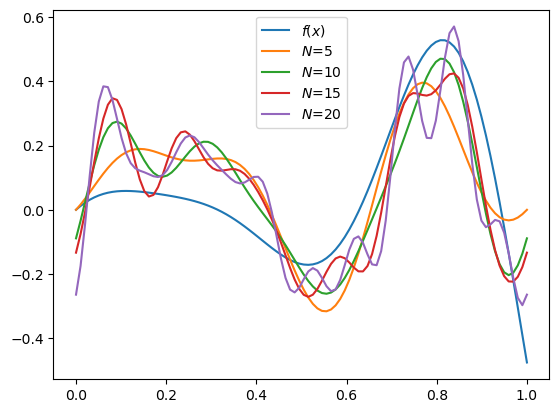

In [69]:
a_list = [5,10,15,20]

plt.plot(t,f(t),label=f'$f(x)$')
for i in a_list:
    plt.plot(t,f_hat(i,t,X,Y),label=f'$N$={i}')
plt.legend()
plt.show()

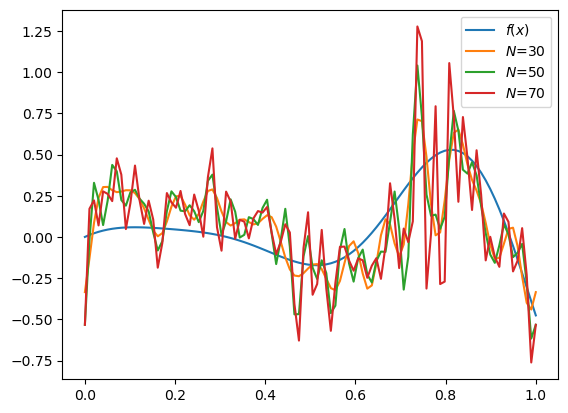

In [71]:
b_list = [30,50,70]

plt.plot(t,f(t),label=f'$f(x)$')
for i in b_list:
    plt.plot(t,f_hat(i,t,X,Y),label=f'$N$={i}')
plt.legend()
plt.show()

(c)

In [31]:
from sklearn.model_selection import KFold

In [46]:
D = np.column_stack((X,Y))
v = 10
kf = KFold(n_splits = v) # fonction de segmnentation (10 groupes)
n = len(X)

def quadratic_loss(y_1,y_2):
    return((y_1-y_2)**2)

N_list = [5,10,15,20,30,50,70]

def error(N,X_test,X_train,Y_train,Y_test):
    e = v/n * np.sum(quadratic_loss(f_hat(N,X_test,X_train,Y_train),Y_test))
    return(e)
    
def cross_val_error(N,X_test,X_train,Y_train,Y_test):
    return(1/v *np.sum(error(N,X_test,X_train,Y_train,Y_test))
           
for train_index, test_index in kf.split(D):
        D_train = D[train_index]
        D_test = D[test_index]
        e = [error(N,D_test[:,0],D_train[:,0],D_train[:,1],D_test[:,1]) for N in N_list]
        CV_val = cross_val_error(N,D_test[:,0],D_train[:,0],D_train[:,1],D_test[:,1])
    N_opt = N_list[np.argmin(CV_val)]